<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Carga eficiente y exploración del Netflix Prize</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Conversión de los ratings a Parquet y a matriz dispersa, separación del probe, exploración de los datos y construcción de la submuestra S.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Preparar los datos del **Netflix Prize** para todos los sistemas de recomendación de la práctica. Convertimos los
~100 millones de ratings de texto a formatos compactos (Parquet, arreglos `numpy` y una matriz dispersa CSR) sin
cargarlos nunca como un `DataFrame` completo, separamos el conjunto **probe** como prueba y exploramos la estructura de
los datos: distribución de los ratings, cola larga, dispersión y evolución en el tiempo. Al final construimos la
**submuestra S**, sobre la que corren los métodos que no escalan a los datos completos.

### Los datos

Archivos de [Netflix Prize (Kaggle)](https://www.kaggle.com/datasets/netflix-inc/netflix-prize-data) en `data/`:

- `combined_data_1.txt` … `combined_data_4.txt`: bloques que empiezan con `MovieID:` seguidos de líneas
  `CustomerID,Rating,Date`.
- `probe.txt`: pares (película, usuario) del conjunto de validación oficial, **sin rating**. Sus ratings están dentro de
  los `combined_data`, así que hay que buscarlos y sacarlos del entrenamiento.
- `movie_titles.csv`: `MovieID,YearOfRelease,Title`, sin encabezado y en latin-1; el título puede tener comas.


### Contenido

0. **Carga eficiente.** Probe, conversión a Parquet por bloques, arreglos de entrenamiento y prueba, matriz CSR y
   catálogo de películas.
1. **Exploración.**
   - 1.1 resumen y dispersión;
   - 1.2 distribución de los ratings;
   - 1.3 actividad de usuarios y películas (cola larga);
   - 1.4 evolución temporal;
   - 1.5 ratings en ráfaga: el efecto del día de alta;
   - 1.6 el probe frente al entrenamiento.
2. **Submuestra S.** Top 5,000 películas × 100,000 usuarios al azar y cuántos ratings del probe quedan dentro.
3. **Resumen y archivos generados.**

In [1]:
# Librerías, rutas, paleta y funciones auxiliares
import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import scipy.sparse as sp
import psutil
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from numba import njit
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

RUTA_DATOS = Path("..") / "data"
RUTA_PROCESADOS = RUTA_DATOS / "processed"
RUTA_PROCESADOS.mkdir(exist_ok=True)
SEMILLA = 42
FECHA_0 = np.datetime64("1998-01-01")  # día 0 de la columna de días (int16)

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    # Estilo común de los ejes: título, etiquetas, sin bordes superior y derecho, rejilla tenue
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    return f"{100 * x:,.{dec}f} %"


def tamano(nbytes):
    return f"{nbytes / 1e9:,.2f} GB" if nbytes >= 1e9 else f"{nbytes / 1e6:,.1f} MB"


registro_ram = []


def ram(paso):
    # Memoria del proceso (RSS) y memoria libre del sistema al terminar un paso
    rss, libre = psutil.Process().memory_info().rss, psutil.virtual_memory().available
    registro_ram.append({"paso": paso, "RAM del proceso": tamano(rss), "RAM libre del sistema": tamano(libre)})
    print(f"[RAM] {paso}: proceso {tamano(rss)} | libre en el sistema {tamano(libre)}")


ram("inicio")

[RAM] inicio: proceso 176.6 MB | libre en el sistema 5.52 GB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">NETFLIX PRIZE · CARGA</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">0. Carga eficiente</span></div>



**0.1 Probe.** Cada par (película, usuario) del probe se codifica como una sola clave entera
$\text{clave} = \text{película} \cdot 2^{22} + \text{usuario}$. Cabe en `int64` porque los IDs de usuario son menores que
$2^{22} \approx 4.19$ millones. Con las claves ordenadas, saber si un rating es del probe es una búsqueda binaria
(`np.searchsorted`), que se hace bloque por bloque al leer los ratings.

In [2]:
# Lectura de probe.txt y claves ordenadas película·2²² + usuario
t0 = time.perf_counter()
probe_txt = pd.read_csv(RUTA_DATOS / "probe.txt", header=None, names=["c"], dtype=str)["c"]
es_encabezado = probe_txt.str.endswith(":")
pelicula = pd.to_numeric(probe_txt.where(es_encabezado).str[:-1]).ffill()[~es_encabezado].to_numpy(np.int64)
usuario = pd.to_numeric(probe_txt[~es_encabezado]).to_numpy(np.int64)
assert usuario.max() < 2 ** 22
claves_probe = np.sort(pelicula * 2 ** 22 + usuario)
assert len(np.unique(claves_probe)) == len(claves_probe)

print(f"probe.txt: {len(probe_txt):,} líneas | {es_encabezado.sum():,} películas | {len(claves_probe):,} pares "
      f"(película, usuario) | {len(np.unique(usuario)):,} usuarios | {time.perf_counter() - t0:.1f} s")
del probe_txt, es_encabezado, pelicula, usuario
gc.collect()
ram("0.1 probe")

probe.txt: 1,425,333 líneas | 16,938 películas | 1,408,395 pares (película, usuario) | 462,858 usuarios | 5.3 s
[RAM] 0.1 probe: proceso 194.0 MB | libre en el sistema 5.53 GB


**0.2 Conversión a Parquet por bloques.** Leemos cada `combined_data_*.txt` con `pandas.read_csv` en bloques de 5
millones de líneas. Las líneas `MovieID:` quedan con rating vacío; su ID se propaga hacia abajo (`ffill`) y se arrastra
al siguiente bloque cuando una película queda partida entre dos. Cada bloque se escribe como un *row group* del mismo
archivo Parquet, con el esquema `user_id` (`int32`), `movie_id` (`int16`), `rating` (`int8`), `date` (`date32`) y la
marca `es_probe`. En memoria nunca hay más que un bloque. Si el Parquet ya existe, no se vuelve a convertir.

In [3]:
# Conversión de los cuatro combined_data_*.txt a data/processed/ratings.parquet
ARCHIVO_RATINGS = RUTA_PROCESADOS / "ratings.parquet"
ARCHIVO_RESUMEN = RUTA_PROCESADOS / "resumen_conversion.parquet"
ESQUEMA = pa.schema([("user_id", pa.int32()), ("movie_id", pa.int16()), ("rating", pa.int8()),
                     ("date", pa.date32()), ("es_probe", pa.bool_())])
BLOQUE = 5_000_000


def convertir(ruta, escritor):
    # Lee un combined_data por bloques y escribe cada bloque al Parquet; devuelve el resumen del archivo
    pelicula_actual, n_peliculas, n_ratings, n_probe = None, 0, 0, 0
    lector = pd.read_csv(ruta, header=None, names=["c", "rating", "date"],
                         dtype={"c": str, "rating": "float32", "date": str}, chunksize=BLOQUE)
    for bloque in lector:
        es_enc = bloque["rating"].isna().to_numpy()
        peli = pd.to_numeric(bloque["c"].where(es_enc).str[:-1])
        if not es_enc[0]:
            peli.iloc[0] = pelicula_actual  # el bloque empieza a la mitad de una película
        peli = peli.ffill()
        pelicula_actual = peli.iloc[-1]

        datos = bloque.loc[~es_enc]
        usuarios = pd.to_numeric(datos["c"]).to_numpy(np.int32)
        peliculas = peli[~es_enc].to_numpy(np.int16)
        claves = peliculas.astype(np.int64) * 2 ** 22 + usuarios
        pos = np.minimum(np.searchsorted(claves_probe, claves), len(claves_probe) - 1)
        en_probe = claves_probe[pos] == claves
        fechas = pd.to_datetime(datos["date"], format="%Y-%m-%d").to_numpy().astype("datetime64[D]")

        escritor.write_table(pa.Table.from_arrays(
            [pa.array(usuarios), pa.array(peliculas), pa.array(datos["rating"].to_numpy(np.int8)),
             pa.array(fechas, type=pa.date32()), pa.array(en_probe)], schema=ESQUEMA))
        n_peliculas += int(es_enc.sum())
        n_ratings += len(datos)
        n_probe += int(en_probe.sum())
    return n_peliculas, n_ratings, n_probe


if ARCHIVO_RATINGS.exists():
    print(f"{ARCHIVO_RATINGS.name} ya existe: no se vuelve a convertir.")
    resumen_conversion = pd.read_parquet(ARCHIVO_RESUMEN)
else:
    filas = []
    with pq.ParquetWriter(ARCHIVO_RATINGS, ESQUEMA, compression="zstd") as escritor:
        for k in range(1, 5):
            ruta = RUTA_DATOS / f"combined_data_{k}.txt"
            t0 = time.perf_counter()
            n_peliculas, n_ratings, n_probe = convertir(ruta, escritor)
            filas.append({"archivo": ruta.name, "tamaño": tamano(ruta.stat().st_size), "películas": n_peliculas,
                          "ratings": n_ratings, "ratings del probe": n_probe,
                          "segundos": round(time.perf_counter() - t0)})
            print(filas[-1])
            gc.collect()
    resumen_conversion = pd.DataFrame(filas)
    resumen_conversion.to_parquet(ARCHIVO_RESUMEN)

total = resumen_conversion[["películas", "ratings", "ratings del probe", "segundos"]].sum()
display(pd.concat([resumen_conversion.set_index("archivo"), total.rename("total").to_frame().T]))
print(f"ratings.parquet: {tamano(ARCHIVO_RATINGS.stat().st_size)} en disco, "
      f"{pq.ParquetFile(ARCHIVO_RATINGS).metadata.num_rows:,} filas, "
      f"{pq.ParquetFile(ARCHIVO_RATINGS).metadata.num_row_groups} row groups")
assert total["ratings del probe"] == len(claves_probe)
ram("0.2 conversión a Parquet")

ratings.parquet ya existe: no se vuelve a convertir.


,tamaño,películas,ratings,ratings del probe,segundos
combined_data_1.txt,495.0 MB,4499,24053764,577213,96
combined_data_2.txt,555.2 MB,4711,26977591,352289,104
combined_data_3.txt,465.2 MB,4157,22601629,245903,97
combined_data_4.txt,552.5 MB,4403,26847523,232990,105
total,NaN,17770,100480507,1408395,402


ratings.parquet: 506.8 MB en disco, 100,480,507 filas, 101 row groups
[RAM] 0.2 conversión a Parquet: proceso 202.3 MB | libre en el sistema 5.53 GB


**0.3 Arreglos de entrenamiento y prueba.** Del Parquet leemos **una columna a la vez** y la partimos con la marca
`es_probe` en dos arreglos `.npy`: entrenamiento (`train_*`) y prueba (`probe_*`). Los índices se pasan a base 0:

- **usuarios:** los IDs van de 1 a ~2.65 millones con huecos; una tabla de búsqueda de 2.65 millones de entradas los
  convierte a `0..n_usuarios − 1` sin ordenar los 100 millones de valores;
- **películas:** `movie_id − 1`, de `0` a `17,769`;
- **fechas:** días desde el 1 de enero de 1998, en `int16`.

In [4]:
# Columnas del Parquet → arreglos .npy de entrenamiento y probe, con usuarios reindexados a 0..n-1
def columna(nombre):
    arreglo = pq.read_table(ARCHIVO_RATINGS, columns=[nombre]).column(0).to_numpy()
    pa.default_memory_pool().release_unused()  # pyarrow conserva su memoria si no se le pide liberarla
    return arreglo


def guardar(nombre, arreglo):
    np.save(RUTA_PROCESADOS / f"train_{nombre}.npy", arreglo[~es_probe])
    np.save(RUTA_PROCESADOS / f"probe_{nombre}.npy", arreglo[es_probe])


t0 = time.perf_counter()
es_probe = columna("es_probe")

ids = columna("user_id")
usuarios_id = np.flatnonzero(np.bincount(ids)).astype(np.int32)  # ID original de cada índice, ordenados
tabla = np.full(ids.max() + 1, -1, dtype=np.int32)
tabla[usuarios_id] = np.arange(len(usuarios_id), dtype=np.int32)
guardar("u", tabla[ids])
np.save(RUTA_PROCESADOS / "usuarios_id.npy", usuarios_id)
del ids, tabla
gc.collect()

guardar("m", (columna("movie_id") - 1).astype(np.int16))
guardar("r", columna("rating").astype(np.int8))
guardar("d", (columna("date") - FECHA_0).astype(np.int16))
n_train, n_probe = int((~es_probe).sum()), int(es_probe.sum())
del es_probe
gc.collect()

memoria = pd.DataFrame([{"arreglo": f"{c}_{x}", "dtype": str(a.dtype), "elementos": f"{a.size:,}", "memoria": tamano(a.nbytes)}
                        for c in ["train", "probe"] for x in "umrd"
                        for a in [np.load(RUTA_PROCESADOS / f"{c}_{x}.npy", mmap_mode="r")]]).set_index("arreglo")
display(memoria)
print(f"Entrenamiento: {n_train:,} ratings | probe: {n_probe:,} | usuarios: {len(usuarios_id):,} | "
      f"{time.perf_counter() - t0:.0f} s")
ram("0.3 arreglos .npy")

,dtype,elementos,memoria
arreglo,,,
train_u,int32,"99,072,112",396.3 MB
train_m,int16,"99,072,112",198.1 MB
train_r,int8,"99,072,112",99.1 MB
train_d,int16,"99,072,112",198.1 MB
probe_u,int32,"1,408,395",5.6 MB
probe_m,int16,"1,408,395",2.8 MB
probe_r,int8,"1,408,395",1.4 MB
probe_d,int16,"1,408,395",2.8 MB


Entrenamiento: 99,072,112 ratings | probe: 1,408,395 | usuarios: 480,189 | 19 s
[RAM] 0.3 arreglos .npy: proceso 1.16 GB | libre en el sistema 4.07 GB


**0.4 Matriz dispersa CSR.** La matriz de ratings de entrenamiento $R$ (usuarios × películas) se guarda en formato CSR
`float32`. Para no pasar por `scipy.sparse.coo_matrix`, que copia los datos varias veces, la armamos con un
**ordenamiento por conteo** compilado con `numba`:

1. el número de ratings de cada usuario (`np.bincount`) da `indptr`;
2. un recorrido de los ratings coloca cada uno en el siguiente hueco libre de su fila.

Como los ratings vienen ordenados por película, las columnas de cada fila quedan ordenadas. Con la misma función
reordenamos también los días, alineados con `R.data`, para los análisis por usuario.

In [5]:
# Ordenamiento por conteo: reacomoda los valores por fila (usuario) según indptr
@njit
def por_filas(filas, valores, indptr, salida):
    pos = indptr[:-1].copy()
    for k in range(len(filas)):
        i = filas[k]
        salida[pos[i]] = valores[k]
        pos[i] += 1
    return salida


def cargar(conjunto):
    return [np.load(RUTA_PROCESADOS / f"{conjunto}_{x}.npy") for x in "umrd"]


t0 = time.perf_counter()
train_u, train_m, train_r, train_d = cargar("train")
n_usuarios, n_peliculas = len(usuarios_id), int(train_m.max()) + 1
indptr = np.zeros(n_usuarios + 1, dtype=np.int64)
indptr[1:] = np.cumsum(np.bincount(train_u, minlength=n_usuarios))
indptr = indptr.astype(np.int32)

indices = por_filas(train_u, train_m, indptr, np.empty(n_train, dtype=np.int32))
datos = por_filas(train_u, train_r, indptr, np.empty(n_train, dtype=np.float32))
R = sp.csr_matrix((datos, indices, indptr), shape=(n_usuarios, n_peliculas))
R.has_sorted_indices = True
dias_csr = por_filas(train_u, train_d, indptr, np.empty(n_train, dtype=np.int16))
del datos, indices
gc.collect()
segundos_csr = time.perf_counter() - t0

assert np.all(np.diff(R.indices[R.indptr[0]:R.indptr[1]]) > 0)
assert R.nnz == n_train and R.data.sum(dtype=np.float64) == train_r.sum(dtype=np.int64)
sp.save_npz(RUTA_PROCESADOS / "R_train.npz", R, compressed=False)
np.save(RUTA_PROCESADOS / "dias_csr.npy", dias_csr)

bytes_csr = R.data.nbytes + R.indices.nbytes + R.indptr.nbytes
bytes_densa = 4 * n_usuarios * n_peliculas
display(pd.Series({
    "Dimensión": f"{n_usuarios:,} × {n_peliculas:,}",
    "Entradas distintas de cero (nnz)": f"{R.nnz:,}",
    "Densidad (nnz / celdas)": pct(R.nnz / (n_usuarios * n_peliculas)),
    "Memoria CSR float32 (data + indices + indptr)": tamano(bytes_csr),
    "Memoria densa float32 (4·n·m, calculada)": tamano(bytes_densa),
    "Ahorro (densa / CSR)": f"{bytes_densa / bytes_csr:,.0f} veces",
    "Tiempo de construcción": f"{segundos_csr:.1f} s",
}, name="Valor").rename_axis("Matriz R (entrenamiento)").to_frame())
ram("0.4 matriz CSR")

,Valor
Matriz R (entrenamiento),
Dimensión,"480,189 × 17,770"
Entradas distintas de cero (nnz),"99,072,112"
Densidad (nnz / celdas),1.16 %
Memoria CSR float32 (data + indices + indptr),794.5 MB
"Memoria densa float32 (4·n·m, calculada)",34.13 GB
Ahorro (densa / CSR),43 veces
Tiempo de construcción,26.8 s


[RAM] 0.4 matriz CSR: proceso 3.09 GB | libre en el sistema 2.32 GB


**0.5 Catálogo de películas.** `movie_titles.csv` no tiene encabezado y los títulos pueden contener comas, así que cada
línea se separa solo en las **dos primeras comas**. Los años `NULL` quedan como faltantes. Agregamos el número de
ratings de entrenamiento y el rating medio de cada película.

In [6]:
# Lectura de movie_titles.csv separando solo por las dos primeras comas, más estadísticas de entrenamiento
with open(RUTA_DATOS / "movie_titles.csv", encoding="latin-1") as f:
    filas = [linea.rstrip("\r\n").split(",", 2) for linea in f]
peliculas = pd.DataFrame(filas, columns=["movie_id", "year", "title"])
peliculas["movie_id"] = peliculas["movie_id"].astype(np.int16)
peliculas["year"] = pd.to_numeric(peliculas["year"].replace("NULL", None)).astype("Int16")
peliculas.insert(0, "m", (peliculas["movie_id"] - 1).astype(np.int16))
assert peliculas["m"].tolist() == list(range(n_peliculas))

peliculas["n_train"] = np.bincount(train_m, minlength=n_peliculas)
peliculas["media_train"] = (np.bincount(train_m, weights=train_r, minlength=n_peliculas)
                            / np.maximum(peliculas["n_train"], 1)).astype(np.float32)
peliculas.to_parquet(RUTA_PROCESADOS / "peliculas.parquet")

print(f"{len(peliculas):,} películas | años de {peliculas['year'].min()} a {peliculas['year'].max()} | "
      f"sin año: {peliculas['year'].isna().sum()} | títulos con comas: {peliculas['title'].str.contains(',').sum():,} | "
      f"títulos repetidos: {peliculas['title'].duplicated(keep=False).sum():,}")
display(peliculas.nlargest(5, "n_train"))
display(peliculas[peliculas["title"].str.contains(",")].head(3))
ram("0.5 catálogo")

17,770 películas | años de 1896 a 2005 | sin año: 7 | títulos con comas: 336 | títulos repetidos: 776


,m,movie_id,year,title,n_train,media_train
5316,5316,5317,2000,Miss Congeniality,227715,3.359230
15123,15123,15124,1996,Independence Day,216233,3.723964
14312,14312,14313,2000,The Patriot,200490,3.783451
15204,15204,15205,2004,The Day After Tomorrow,194695,3.442564
6286,6286,6287,1990,Pretty Woman,190320,3.901361


,m,movie_id,year,title,n_train,media_train
71,71,72,1974,"At Home Among Strangers, A Stranger Among His Own",173,3.121387
263,263,264,2002,"Angelina Ballerina: Lights, Camera, Action!",132,2.871212
349,349,350,1993,"Dr. Quinn, Medicine Woman: Season 3",1117,3.790510


[RAM] 0.5 catálogo: proceso 2.20 GB | libre en el sistema 3.27 GB


**Observaciones: carga eficiente**

- **Probe.** Tiene **1,408,395** pares (película, usuario) de **16,938** películas y **462,858** usuarios. Los encontramos
  **todos** dentro de los `combined_data` (lo comprueba un `assert`), así que la partición es exacta: **99,072,112** ratings
  de entrenamiento y **1,408,395** de prueba, que suman los **100,480,507** del concurso.
- **Conversión.** Los 2.07 GB de texto se convierten en unos **7 minutos** (402 s) a un Parquet de **506.8 MB** con
  compresión zstd, cuatro veces menos espacio. Al terminar, el proceso ocupa **201 MB**: como se escribe bloque por bloque,
  los 100 millones de ratings nunca están juntos en memoria.
- **Arreglos compactos.** Con `int32` + `int16` + `int8` + `int16`, cada rating ocupa **9 bytes** y el entrenamiento
  completo, **892 MB** en cuatro arreglos. Un `DataFrame` con columnas `int64` y fechas ocuparía más de 3 GB.
- **Matriz CSR.** $R$ es de **480,189 × 17,770** con densidad **1.16 %**. En CSR ocupa **794.5 MB**, contra
  **34.13 GB** de la versión densa: **43 veces** menos. El ahorro es mucho menor que en las redes de la práctica 3 porque
  esta matriz es relativamente densa y cada entrada guarda un índice y un valor. El ordenamiento por conteo la arma en
  **27 s**.
- **Memoria.** El pico es de **3.11 GB** en el paso 0.4, cuando conviven los cuatro arreglos de entrenamiento, $R$ y los
  días alineados. Quedan **2.5 GB** libres en el sistema. Después de 0.3 el proceso sigue en 1.18 GB aunque los arreglos
  ya se liberaron: es memoria que el asignador aún no devuelve al sistema y que se reutiliza en los pasos siguientes.
- **Catálogo.** **7** películas no tienen año y **336** títulos tienen comas, que la separación por las dos primeras
  comas conserva. Además, **776** títulos están repetidos (remakes, temporadas o ediciones con el mismo nombre). En las
  recomendaciones identificaremos cada película por título **y** año.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">NETFLIX PRIZE · EXPLORACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Exploración</span></div>



Toda la exploración se hace sobre los arreglos de entrenamiento y la matriz $R$; el probe se usa solo para compararlo
con el entrenamiento (1.2 y 1.6).

**1.1 Resumen y dispersión.**

In [7]:
# Resumen del conjunto completo y de la partición entrenamiento / probe
probe_u, probe_m, probe_r, probe_d = cargar("probe")
n_por_usuario = np.diff(R.indptr)
n_por_pelicula = peliculas["n_train"].to_numpy()
a_fecha = lambda d: str(FECHA_0 + np.timedelta64(int(d), "D"))

display(pd.Series({
    "Ratings totales": f"{n_train + n_probe:,}",
    "Entrenamiento / probe": f"{n_train:,} / {n_probe:,} ({pct(n_probe / (n_train + n_probe))} en el probe)",
    "Usuarios / películas": f"{n_usuarios:,} / {n_peliculas:,}",
    "Usuarios con ratings en el probe": f"{len(np.unique(probe_u)):,} ({pct(len(np.unique(probe_u)) / n_usuarios)})",
    "Usuarios sin ratings de entrenamiento": f"{(n_por_usuario == 0).sum():,}",
    "Celdas observadas (densidad)": pct((n_train + n_probe) / (n_usuarios * n_peliculas)),
    "Celdas vacías (sparsity)": pct(1 - (n_train + n_probe) / (n_usuarios * n_peliculas)),
    "Rating medio: entrenamiento / probe": f"{train_r.mean():.4f} / {probe_r.mean():.4f}",
    "Fechas del entrenamiento": f"{a_fecha(train_d.min())} a {a_fecha(train_d.max())}",
    "Fechas del probe": f"{a_fecha(probe_d.min())} a {a_fecha(probe_d.max())}",
}, name="Valor").rename_axis("Métrica").to_frame())

,Valor
Métrica,
Ratings totales,"100,480,507"
Entrenamiento / probe,"99,072,112 / 1,408,395 (1.40 % en el probe)"
Usuarios / películas,"480,189 / 17,770"
Usuarios con ratings en el probe,"462,858 (96.39 %)"
Usuarios sin ratings de entrenamiento,0
Celdas observadas (densidad),1.18 %
Celdas vacías (sparsity),98.82 %
Rating medio: entrenamiento / probe,3.6033 / 3.6736
Fechas del entrenamiento,1999-11-11 a 2005-12-31


**1.2 Distribución de los ratings.**

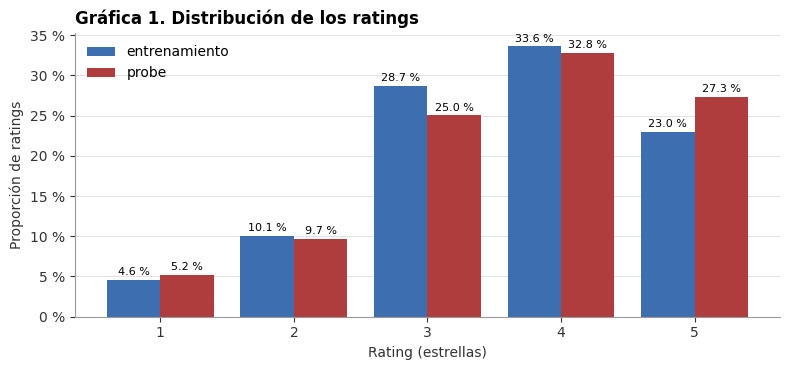

,1,2,3,4,5
entrenamiento,4.59 %,10.09 %,28.73 %,33.60 %,23.00 %
probe,5.20 %,9.66 %,25.02 %,32.81 %,27.31 %


In [8]:
# Gráfica 1. Proporción de cada rating en entrenamiento y probe
dist = pd.DataFrame({"entrenamiento": np.bincount(train_r, minlength=6)[1:] / n_train,
                     "probe": np.bincount(probe_r, minlength=6)[1:] / n_probe}, index=range(1, 6))
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(1, 6)
for desplaz, (col, color) in zip([-0.2, 0.2], [("entrenamiento", AZUL), ("probe", ROJO)]):
    barras = ax.bar(x + desplaz, dist[col], width=0.4, color=color, label=col)
    ax.bar_label(barras, labels=[pct(v, 1) for v in dist[col]], fontsize=8, padding=2)
ax.set_xticks(x)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v, 0)))
ax.legend()
estilo_ejes(ax, "Gráfica 1. Distribución de los ratings", "Rating (estrellas)", "Proporción de ratings")
plt.tight_layout()
plt.show()
display(dist.map(lambda v: pct(v, 2)).T)

**Observaciones: distribución de los ratings**

- **La escala está cargada hacia arriba.** El 4 es el rating más común (**33.6 %**) y 4 o 5 suman **56.6 %** del
  entrenamiento; 1 y 2 juntos son solo **14.7 %**. Los usuarios califican sobre todo lo que eligieron ver, así que los
  ratings faltantes **no son al azar**.
- **El probe es más extremo.** Tiene más 5 (**27.3 %** contra 23.0 %) y más 1 (**5.2 %** contra 4.6 %), y un rating medio
  más alto (**3.674** contra 3.603). Es lo esperado si el probe tiene los ratings más recientes, que en 1.4 veremos que
  son más altos. Por eso la media global del entrenamiento sola no basta como predictor: los sesgos de usuario y de
  película del notebook 2 deben capturar esa diferencia.

**1.3 Actividad de usuarios y películas (cola larga).** Para cada usuario y cada película contamos sus ratings de
entrenamiento. La Gráfica 2 muestra en log-log la proporción de usuarios (o películas) con al menos $x$ ratings, y la
curva de concentración: qué parte de los ratings se lleva el top de películas (o usuarios) más calificado.

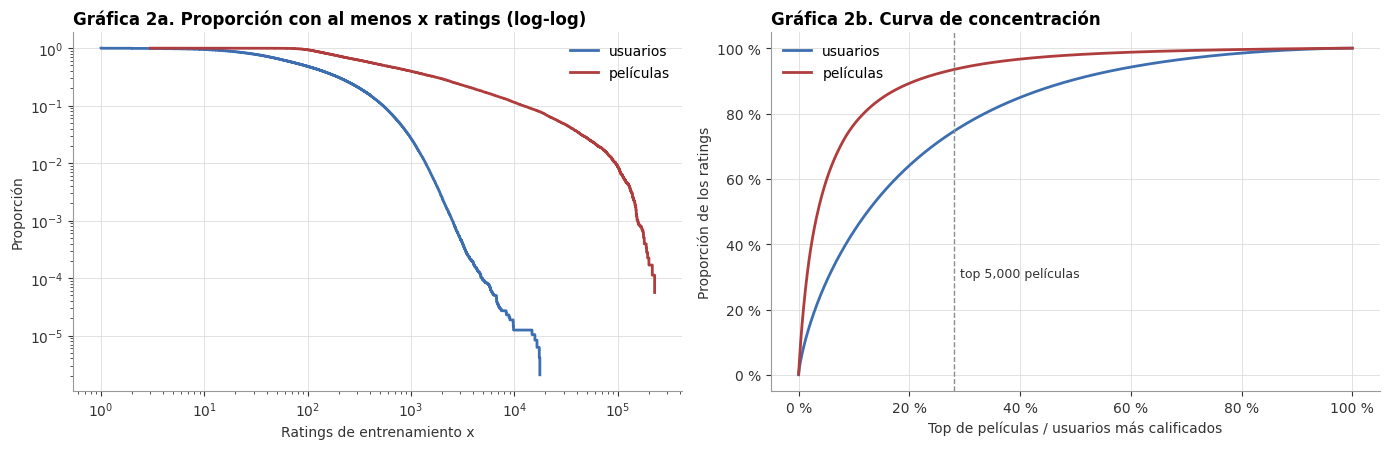

,cuantil 0,cuantil 0.1,cuantil 0.25,cuantil 0.5,cuantil 0.75,cuantil 0.9,cuantil 0.99,cuantil 1
ratings por usuario,1,16,36,93,256,538,1387,17651
ratings por película,3,114,186,546,2633,12152,95016,227715


Top 5,000 películas (28.1 %): 93.51 % de los ratings | top 1 % de usuarios: 9.19 %
Películas con < 100 ratings: 1,102 | usuarios con < 20 ratings: 62,452 (13.01 %) | usuarios con > 5,000: 43 | máximo: 17,651


In [9]:
# Gráfica 2. Distribución de la actividad (log-log) y curva de concentración
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
for valores, color, etiqueta in [(n_por_usuario, AZUL, "usuarios"), (n_por_pelicula, ROJO, "películas")]:
    v = np.sort(valores[valores > 0])
    ax1.step(v, 1 - np.arange(len(v)) / len(v), where="post", color=color, linewidth=2, label=etiqueta)
    acumulado = np.cumsum(v[::-1]) / v.sum()
    ax2.plot(np.arange(1, len(v) + 1) / len(v), acumulado, color=color, linewidth=2, label=etiqueta)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.legend()
estilo_ejes(ax1, "Gráfica 2a. Proporción con al menos x ratings (log-log)", "Ratings de entrenamiento x",
            "Proporción", rejilla="both")
ax2.axvline(5000 / n_peliculas, color=GRIS, linestyle="--", linewidth=1)
ax2.text(5000 / n_peliculas + 0.01, 0.3, "top 5,000 películas", fontsize=9, color=TINTA)
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v, 0)))
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v, 0)))
ax2.legend()
estilo_ejes(ax2, "Gráfica 2b. Curva de concentración", "Top de películas / usuarios más calificados",
            "Proporción de los ratings", rejilla="both")
plt.tight_layout()
plt.show()


def concentracion(valores, k):
    return np.sort(valores)[::-1][:k].sum() / valores.sum()


cuantiles = [0, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 1]
display(pd.DataFrame({"ratings por usuario": np.quantile(n_por_usuario, cuantiles),
                      "ratings por película": np.quantile(n_por_pelicula, cuantiles)},
                     index=[f"cuantil {q:g}" for q in cuantiles]).astype(int).T)
print(f"Top 5,000 películas ({pct(5000 / n_peliculas, 1)}): {pct(concentracion(n_por_pelicula, 5000))} de los ratings | "
      f"top 1 % de usuarios: {pct(concentracion(n_por_usuario, n_usuarios // 100))}")
print(f"Películas con < 100 ratings: {(n_por_pelicula < 100).sum():,} | usuarios con < 20 ratings: "
      f"{(n_por_usuario < 20).sum():,} ({pct((n_por_usuario < 20).mean())}) | usuarios con > 5,000: "
      f"{(n_por_usuario > 5000).sum():,} | máximo: {n_por_usuario.max():,}")

**Observaciones: cola larga**

- **Películas.** La mediana es de **546** ratings, pero el promedio lo jalan unas cuantas: *Miss Congeniality* tiene
  **227,715**. Las **5,000** películas más calificadas (**28.1 %** del catálogo) concentran el **93.5 %** de los ratings
  (Gráfica 2b), y **1,102** películas tienen menos de 100.
- **Usuarios.** La mediana es de **93** ratings y el 90 % tiene menos de **538**. **62,452** usuarios (**13.0 %**) tienen
  menos de 20 y **43** tienen más de 5,000; el máximo, **17,651**, casi todo el catálogo. La concentración es menor que la
  de las películas: el 1 % más activo aporta el **9.2 %** de los ratings.
- **En log-log (Gráfica 2a)** ninguna de las dos curvas es una recta: no son leyes de potencias puras, sino distribuciones
  con una caída cada vez más rápida.
- **Consecuencias para los modelos.**
  - Los sesgos y factores de películas y usuarios con pocos ratings son poco confiables, así que hay que **regularizar**
    (notebooks 2 y 3).
  - El soporte de las reglas de asociación lo dominarán las películas populares (notebook 4).
  - La concentración justifica la submuestra S: con 5,000 películas perdemos solo el 6.5 % de los ratings.

**1.4 Evolución temporal.** Agrupamos los ratings por mes de calificación. Recordemos que la fecha es la del rating, no
la de cuándo se vio la película.

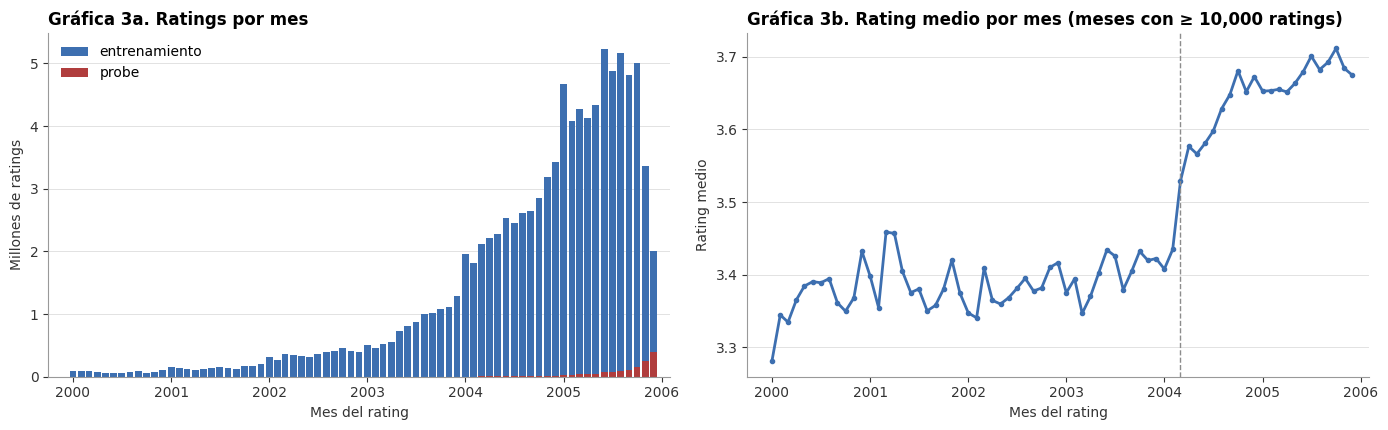

mes,1999,2000,2001,2002,2003,2004,2005
ratings,"2,178","923,829","1,767,979","4,339,314","9,973,709","30,117,910","51,947,193"
% del entrenamiento,0.0 %,0.9 %,1.8 %,4.4 %,10.1 %,30.4 %,52.4 %
rating medio,3.337,3.365,3.391,3.382,3.406,3.595,3.676
% del probe,0.0 %,0.0 %,0.1 %,0.3 %,0.8 %,6.3 %,92.5 %


Rating medio 2003-01 a 2004-02: 3.410 | 2004-03 a 2004-12: 3.619


In [10]:
# Gráfica 3. Ratings por mes y rating medio mensual, entrenamiento y probe
dias = np.arange(max(train_d.max(), probe_d.max()) + 1)
mes_de_dia = ((FECHA_0 + dias.astype("timedelta64[D]")).astype("datetime64[M]") - np.datetime64("1998-01", "M")).astype(int)
meses = pd.period_range("1998-01", periods=mes_de_dia.max() + 1, freq="M").to_timestamp()

n_mes = np.bincount(mes_de_dia[train_d], minlength=len(meses))
media_mes = np.bincount(mes_de_dia[train_d], weights=train_r, minlength=len(meses)) / np.maximum(n_mes, 1)
n_mes_probe = np.bincount(mes_de_dia[probe_d], minlength=len(meses))
validos = n_mes >= 10_000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
ax1.bar(meses, n_mes / 1e6, width=25, color=AZUL, label="entrenamiento")
ax1.bar(meses, n_mes_probe / 1e6, width=25, color=ROJO, label="probe")
ax1.set_xlim(pd.Timestamp("1999-10-01"), pd.Timestamp("2006-02-01"))
ax1.legend()
estilo_ejes(ax1, "Gráfica 3a. Ratings por mes", "Mes del rating", "Millones de ratings")
ax2.set_xlim(pd.Timestamp("1999-10-01"), pd.Timestamp("2006-02-01"))
ax2.plot(meses[validos], media_mes[validos], color=AZUL, linewidth=2, marker="o", markersize=3)
ax2.axvline(pd.Timestamp("2004-03-01"), color=GRIS, linestyle="--", linewidth=1)
estilo_ejes(ax2, "Gráfica 3b. Rating medio por mes (meses con ≥ 10,000 ratings)", "Mes del rating", "Rating medio")
plt.tight_layout()
plt.show()

por_anio = pd.DataFrame({"mes": meses, "n": n_mes, "suma": media_mes * n_mes, "probe": n_mes_probe})
por_anio = por_anio.groupby(por_anio["mes"].dt.year)[["n", "suma", "probe"]].sum().query("n > 0")
display(pd.DataFrame({"ratings": por_anio["n"].map("{:,}".format),
                      "% del entrenamiento": (por_anio["n"] / n_train).map(lambda v: pct(v, 1)),
                      "rating medio": (por_anio["suma"] / por_anio["n"]).round(3),
                      "% del probe": (por_anio["probe"] / n_probe).map(lambda v: pct(v, 1))}).T)
antes, despues = (meses >= "2003-01-01") & (meses < "2004-03-01"), (meses >= "2004-03-01") & (meses < "2005-01-01")
print(f"Rating medio 2003-01 a 2004-02: {np.average(media_mes[antes], weights=n_mes[antes]):.3f} | "
      f"2004-03 a 2004-12: {np.average(media_mes[despues], weights=n_mes[despues]):.3f}")

**Observaciones: evolución temporal**

- **El volumen crece exponencialmente (Gráfica 3a).** **2004** y **2005** concentran el **82.8 %** del entrenamiento;
  antes de 2002 hay menos del 3 %. El último mes, diciembre de 2005, está incompleto.
- **El probe está al final del tiempo.** El **92.5 %** de sus ratings es de 2005 y el 6.3 % de 2004.
- **Hay un salto en el rating medio a principios de 2004 (Gráfica 3b).** De enero de 2003 a febrero de 2004 el promedio es
  **3.410**; de marzo a diciembre de 2004 sube a **3.619** y sigue en ~3.68 durante 2005. Koren (2009) documenta este cambio
  y lo atribuye a cambios de Netflix en esas fechas, como la redacción de las estrellas. No es un cambio en las películas.
- **Implicación.** Como el probe es casi todo de 2005, un modelo entrenado con todo el periodo hereda una media más baja
  que la del probe. No modelamos la dinámica temporal (timeSVD++ de Koren queda fuera del alcance), pero los sesgos de
  usuario absorben parte del efecto, porque cada usuario califica sobre todo en un periodo corto.

**1.5 Ratings en ráfaga: el efecto del día de alta.** Si muchos usuarios calificaron decenas de películas el mismo día,
el orden por fecha no es el orden en que las vieron. Esto importa para los patrones secuenciales del notebook 4. Para
cada usuario contamos sus días distintos con ratings y su día con más ratings, y llamamos **ráfaga** a un día con 20
o más ratings del mismo usuario. Lo calculamos con un recorrido por fila sobre los días alineados con la CSR.

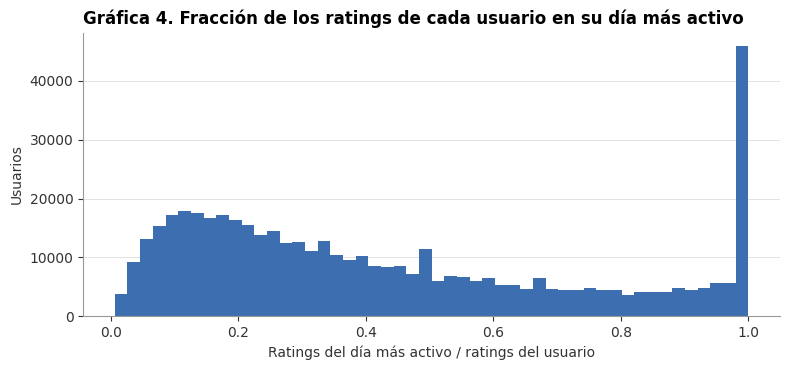

,Valor
Ráfagas (≥ 20 ratings en un día),
Ratings por día de actividad (mediana por usuario),5.9
Fracción de ratings en el día más activo (mediana),34.9 %
Usuarios con al menos un día de ráfaga,64.4 %
Ratings que caen en días de ráfaga,56.9 %
Usuarios con todos sus ratings en un solo día,9.0 %
Máximo de ratings de un usuario en un día,"5,446"


In [11]:
# Días distintos, máximo de ratings en un día y ratings en días de ráfaga (≥ 20), por usuario
UMBRAL_RAFAGA = 20


@njit
def dias_por_usuario(indptr, dias, n_dias, umbral):
    n = len(indptr) - 1
    distintos, maximo, en_rafaga = np.zeros(n, np.int32), np.zeros(n, np.int32), np.zeros(n, np.int32)
    cuenta = np.zeros(n_dias, np.int32)
    for i in range(n):
        for k in range(indptr[i], indptr[i + 1]):
            cuenta[dias[k]] += 1
        for k in range(indptr[i], indptr[i + 1]):
            c = cuenta[dias[k]]
            if c > 0:  # primera vez que se ve ese día en la fila: se cuenta y se reinicia
                distintos[i] += 1
                maximo[i] = max(maximo[i], c)
                if c >= umbral:
                    en_rafaga[i] += c
                cuenta[dias[k]] = 0
    return distintos, maximo, en_rafaga


distintos, maximo_dia, en_rafaga = dias_por_usuario(R.indptr, dias_csr, len(dias), UMBRAL_RAFAGA)
activos = n_por_usuario > 0
frac_max = maximo_dia[activos] / n_por_usuario[activos]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(frac_max, bins=50, color=AZUL)
estilo_ejes(ax, "Gráfica 4. Fracción de los ratings de cada usuario en su día más activo",
            "Ratings del día más activo / ratings del usuario", "Usuarios")
plt.tight_layout()
plt.show()

display(pd.Series({
    "Ratings por día de actividad (mediana por usuario)": f"{np.median(n_por_usuario[activos] / distintos[activos]):.1f}",
    "Fracción de ratings en el día más activo (mediana)": pct(np.median(frac_max), 1),
    "Usuarios con al menos un día de ráfaga": pct((maximo_dia[activos] >= UMBRAL_RAFAGA).mean(), 1),
    "Ratings que caen en días de ráfaga": pct(en_rafaga.sum() / n_train, 1),
    "Usuarios con todos sus ratings en un solo día": pct((distintos[activos] == 1).mean(), 1),
    "Máximo de ratings de un usuario en un día": f"{maximo_dia.max():,}",
}, name="Valor").rename_axis(f"Ráfagas (≥ {UMBRAL_RAFAGA} ratings en un día)").to_frame())

**Observaciones y decisión: ratings en ráfaga**

- **Las ráfagas son la norma.** El **64.4 %** de los usuarios tiene al menos un día con 20 o más ratings, y en esos días
  cae el **56.9 %** de todos los ratings.
  - La mediana de ratings por día de actividad es **5.9**, y la mitad de los usuarios concentra al menos el **34.9 %** de
    sus ratings en su día más activo.
  - El pico en 1.0 de la Gráfica 4 son los **9.0 %** de usuarios que calificaron **todo en un solo día**. Un usuario llegó a
    **5,446** ratings en un día.
- **Interpretación.** Calificar en masa es lo que pedía Netflix al darse de alta: el usuario recorre listas y califica lo
  que vio hace tiempo. La fecha dice cuándo calificó, no cuándo vio la película.
- **Decisión para PrefixSpan (notebook 4).** Las películas calificadas el **mismo día** forman un solo *itemset* de la
  secuencia, sin un orden inventado dentro del día. La recomendación de la "siguiente película" se interpretará como lo
  siguiente que el usuario **calificó**.

**1.6 El probe frente al entrenamiento.** Según la documentación del concurso, el probe se armó con los ratings **más
recientes** de cada usuario y con más peso para los usuarios poco activos. Lo comprobamos: comparamos la actividad de
los usuarios del probe con la de todos, el número de ratings de probe por usuario y la fecha de cada rating del probe
contra el último rating de entrenamiento de su usuario.

In [12]:
# Actividad de los usuarios del probe, ratings de probe por usuario y recencia frente al último rating de entrenamiento
ultimo_dia = np.maximum.reduceat(dias_csr, R.indptr[:-1][activos])  # filas no vacías, en orden
ultimo = np.full(n_usuarios, -1, dtype=np.int32)
ultimo[activos] = ultimo_dia
probe_por_usuario = np.bincount(probe_u, minlength=n_usuarios)
usuarios_probe = probe_por_usuario > 0
con_train = ultimo[probe_u] >= 0
desfase = (probe_d - ultimo[probe_u])[con_train]

display(pd.DataFrame({
    "todos los usuarios": np.quantile(n_por_usuario, [0.25, 0.5, 0.75, 0.9]),
    "usuarios con probe": np.quantile(n_por_usuario[usuarios_probe], [0.25, 0.5, 0.75, 0.9]),
}, index=["cuantil 0.25", "mediana", "cuantil 0.75", "cuantil 0.9"]).astype(int).T.rename_axis("Ratings de entrenamiento"))

display(pd.Series({
    "Ratings de probe por usuario (mín / mediana / máx)": f"{probe_por_usuario[usuarios_probe].min()} / "
        f"{np.median(probe_por_usuario[usuarios_probe]):.0f} / {probe_por_usuario.max()}",
    "Probe con fecha ≥ último rating de entrenamiento del usuario": pct((desfase >= 0).mean(), 1),
    "Probe el mismo día que el último rating de entrenamiento": pct((desfase == 0).mean(), 1),
    "Desfase mediano en días (probe − último de entrenamiento)": f"{np.median(desfase):.0f}",
    "Probe / entrenamiento en usuarios con < 50 ratings": pct(probe_por_usuario[n_por_usuario < 50].sum()
                                                             / n_por_usuario[n_por_usuario < 50].sum()),
    "Probe / entrenamiento en usuarios con ≥ 500 ratings": pct(probe_por_usuario[n_por_usuario >= 500].sum()
                                                              / n_por_usuario[n_por_usuario >= 500].sum()),
}, name="Valor").rename_axis("Probe").to_frame())
del ultimo_dia, desfase, distintos, maximo_dia, en_rafaga, frac_max
gc.collect()
ram("1. exploración")

,cuantil 0.25,mediana,cuantil 0.75,cuantil 0.9
Ratings de entrenamiento,,,,
todos los usuarios,36,93,256,538
usuarios con probe,37,95,259,541


,Valor
Probe,
Ratings de probe por usuario (mín / mediana / máx),1 / 3 / 9
Probe con fecha ≥ último rating de entrenamiento del usuario,100.0 %
Probe el mismo día que el último rating de entrenamiento,37.0 %
Desfase mediano en días (probe − último de entrenamiento),10
Probe / entrenamiento en usuarios con < 50 ratings,11.30 %
Probe / entrenamiento en usuarios con ≥ 500 ratings,0.35 %


[RAM] 1. exploración: proceso 2.25 GB | libre en el sistema 3.25 GB


**Observaciones: el probe frente al entrenamiento**

- **El probe son los últimos ratings de cada usuario.** El **100 %** tiene una fecha igual o posterior al último rating de
  entrenamiento de su usuario: el **37.0 %** el mismo día y con un desfase mediano de **10** días. Para evaluar es lo
  más realista que podemos hacer: predecir el futuro a partir del pasado.
- **Cada usuario aporta pocos ratings.** El **96.4 %** de los usuarios tiene probe, con entre **1** y **9** ratings y una
  mediana de **3**. La actividad de los usuarios del probe es la de todos (mediana **95** contra 93).
- **Por eso pesa más en los usuarios poco activos.** En los usuarios con menos de 50 ratings, el probe equivale al
  **11.3 %** de su entrenamiento; en los que tienen 500 o más, al **0.35 %**. Al ponderar por ratings, el RMSE del probe lo
  dominan usuarios con poca historia, y es más alto que el de una partición al azar.
- **Referencia.** Por eso comparamos contra el RMSE de **Cinematch en el probe (0.9474)**, no contra el del conjunto
  *quiz* (0.9514).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">NETFLIX PRIZE · SUBMUESTRA</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Submuestra S</span></div>



Los métodos que no escalan a 100 millones de ratings (kNN ítem-ítem, NMF, reglas de asociación, PrefixSpan, grafos y
contenido) corren sobre la **submuestra S**, y todos los modelos se comparan sobre la parte del probe que cae dentro de
ella. La definimos así:

- **Películas:** las **5,000 con más ratings de entrenamiento**. Por la cola larga (1.3), cubren casi todos los ratings
  y descartan películas con muy pocos datos para cualquier método.
- **Usuarios:** **100,000 al azar** de los 480,189 (semilla 42), **no** los más activos. Los más activos tienen miles
  de ratings y sesgarían la evaluación, sobre todo porque el probe da más peso a los usuarios poco activos (1.6).

Las filas y columnas de S se reindexan a `0..99,999` y `0..4,999`. Guardamos las tablas de correspondencia con los
índices globales.

In [13]:
# Construcción de S: top 5,000 películas × 100,000 usuarios al azar, con su parte del probe
N_PELICULAS_S, N_USUARIOS_S = 5_000, 100_000
S_peliculas = np.sort(np.argsort(-n_por_pelicula, kind="stable")[:N_PELICULAS_S]).astype(np.int16)
S_usuarios = np.sort(np.random.default_rng(SEMILLA).choice(n_usuarios, N_USUARIOS_S, replace=False)).astype(np.int32)
local_pel = np.full(n_peliculas, -1, dtype=np.int32)
local_pel[S_peliculas] = np.arange(N_PELICULAS_S)
local_usr = np.full(n_usuarios, -1, dtype=np.int32)
local_usr[S_usuarios] = np.arange(N_USUARIOS_S)


def recortar(u, m, r, d):
    # Ratings de un conjunto que caen en S, con índices locales
    dentro = (local_usr[u] >= 0) & (local_pel[m] >= 0)
    return local_usr[u[dentro]], local_pel[m[dentro]], r[dentro], d[dentro]


su, sm, sr, sd = recortar(train_u, train_m, train_r, train_d)
S_indptr = np.zeros(N_USUARIOS_S + 1, dtype=np.int32)
S_indptr[1:] = np.cumsum(np.bincount(su, minlength=N_USUARIOS_S))
S_R = sp.csr_matrix((por_filas(su, sr, S_indptr, np.empty(len(su), np.float32)),
                     por_filas(su, sm, S_indptr, np.empty(len(su), np.int32)), S_indptr),
                    shape=(N_USUARIOS_S, N_PELICULAS_S))
S_dias = por_filas(su, sd, S_indptr, np.empty(len(su), np.int16))
del su, sm, sr, sd
pu, pm, pr_, pd_ = recortar(probe_u, probe_m, probe_r, probe_d)

sp.save_npz(RUTA_PROCESADOS / "S_R_train.npz", S_R, compressed=False)
np.save(RUTA_PROCESADOS / "S_dias.npy", S_dias)
np.save(RUTA_PROCESADOS / "S_peliculas.npy", S_peliculas)
np.save(RUTA_PROCESADOS / "S_usuarios.npy", S_usuarios)
for nombre, arreglo in zip("umrd", [pu, pm, pr_, pd_]):
    np.save(RUTA_PROCESADOS / f"S_probe_{nombre}.npy", arreglo)

probe_de_S = np.isin(probe_u, S_usuarios)
n_S = np.diff(S_R.indptr)
display(pd.Series({
    "Dimensión de S": f"{N_USUARIOS_S:,} × {N_PELICULAS_S:,}",
    "Ratings de entrenamiento en S": f"{S_R.nnz:,} ({pct(S_R.nnz / n_train)} del total)",
    "Densidad de S": pct(S_R.nnz / (N_USUARIOS_S * N_PELICULAS_S)),
    "Ratings de los 100,000 usuarios que S conserva": pct(S_R.nnz / n_por_usuario[S_usuarios].sum()),
    "Usuarios de S sin ratings de entrenamiento en S": f"{(n_S == 0).sum():,}",
    "Ratings por usuario en S (mediana / media)": f"{np.median(n_S):.0f} / {n_S.mean():.1f}",
    "Probe dentro de S": f"{len(pu):,} ({pct(len(pu) / n_probe)} del probe)",
    "Probe de los usuarios de S en películas fuera del top 5,000": f"{probe_de_S.sum() - len(pu):,} "
        f"({pct(1 - len(pu) / probe_de_S.sum())} de su probe)",
    "Usuarios de S con probe en S": f"{len(np.unique(pu)):,}",
    "Probe en S sin ratings de entrenamiento del usuario en S": f"{(n_S[pu] == 0).sum():,}",
    "Rating medio: entrenamiento S / probe S": f"{S_R.data.mean():.4f} / {pr_.mean():.4f}",
    "Memoria de S (CSR)": tamano(S_R.data.nbytes + S_R.indices.nbytes + S_R.indptr.nbytes),
}, name="Valor").rename_axis("Submuestra S").to_frame())
ram("2. submuestra S")

,Valor
Submuestra S,
Dimensión de S,"100,000 × 5,000"
Ratings de entrenamiento en S,"19,333,679 (19.51 % del total)"
Densidad de S,3.87 %
"Ratings de los 100,000 usuarios que S conserva",93.36 %
Usuarios de S sin ratings de entrenamiento en S,100
Ratings por usuario en S (mediana / media),88 / 193.3
Probe dentro de S,"262,954 (18.67 % del probe)"
"Probe de los usuarios de S en películas fuera del top 5,000","30,038 (10.25 % de su probe)"
Usuarios de S con probe en S,"94,051"


[RAM] 2. submuestra S: proceso 2.45 GB | libre en el sistema 2.88 GB


**Observaciones: submuestra S**

- **Tamaño.** S tiene **19,333,679** ratings de entrenamiento (**19.5 %** del total) en una matriz de **100,000 × 5,000**
  con densidad **3.87 %**, 3.3 veces más densa que $R$. En CSR ocupa **155 MB**, así que caben los métodos más costosos.
- **Lo que conserva.** Para los 100,000 usuarios elegidos, S guarda el **93.4 %** de sus ratings, casi la misma proporción
  que cubren las 5,000 películas en todo el conjunto (93.5 %). La mediana es de **88** ratings por usuario y la media de
  **193.3**, cerca de las del conjunto completo (93 y 206) y un poco menores por el recorte de películas: el muestreo
  al azar no sesgó la actividad. Solo **100** usuarios se quedan
  sin ratings en S.
- **Probe dentro de S: 262,954 ratings** (**18.67 %** del probe) de **94,051** usuarios. Es el conjunto de prueba común
  para comparar todos los modelos en el notebook 6.
  - Perdemos **30,038** ratings del probe de esos usuarios (**10.25 %**) por caer en películas fuera del top 5,000. Es
    más que el 6.5 % del entrenamiento que se pierde, porque el probe es reciente y tiene más películas nuevas, todavía con
    pocos ratings.
  - Solo **23** ratings del probe en S son de usuarios sin entrenamiento en S. Ahí los modelos recurren al sesgo de la
    película.
- **Rating medio.** Es **3.623** en el entrenamiento de S y **3.694** en su probe, la misma brecha de ~0.07 del conjunto
  completo.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">NETFLIX PRIZE · RESUMEN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Resumen y archivos generados</span></div>



Liberamos los arreglos completos y dejamos el registro de memoria de cada paso y los archivos que leen los notebooks
siguientes.

In [14]:
# Liberación de memoria, registro de RAM por paso y archivos de data/processed/
del R, dias_csr, train_u, train_m, train_r, train_d, probe_u, probe_m, probe_r, probe_d, S_R, S_dias
gc.collect()
ram("3. después de liberar")
display(pd.DataFrame(registro_ram).set_index("paso"))

archivos = sorted(RUTA_PROCESADOS.iterdir())
display(pd.DataFrame({"archivo": [a.name for a in archivos],
                      "tamaño": [tamano(a.stat().st_size) for a in archivos]}).set_index("archivo").T)

[RAM] 3. después de liberar: proceso 361.8 MB | libre en el sistema 4.97 GB


,RAM del proceso,RAM libre del sistema
paso,,
inicio,176.6 MB,5.52 GB
0.1 probe,194.0 MB,5.53 GB
0.2 conversión a Parquet,202.3 MB,5.53 GB
0.3 arreglos .npy,1.16 GB,4.07 GB
0.4 matriz CSR,3.09 GB,2.32 GB
0.5 catálogo,2.20 GB,3.27 GB
1. exploración,2.25 GB,3.25 GB
2. submuestra S,2.45 GB,2.88 GB
3. después de liberar,361.8 MB,4.97 GB


archivo,dias_csr.npy,peliculas.parquet,probe_d.npy,probe_m.npy,probe_r.npy,probe_u.npy,R_train.npz,ratings.parquet,resumen_conversion.parquet,S_dias.npy,S_peliculas.npy,S_probe_d.npy,S_probe_m.npy,S_probe_r.npy,S_probe_u.npy,S_R_train.npz,S_usuarios.npy,train_d.npy,train_m.npy,train_r.npy,train_u.npy,usuarios_id.npy
tamaño,198.1 MB,0.7 MB,2.8 MB,2.8 MB,1.4 MB,5.6 MB,794.5 MB,506.8 MB,0.0 MB,38.7 MB,0.0 MB,0.5 MB,1.1 MB,0.3 MB,1.1 MB,155.1 MB,0.4 MB,198.1 MB,198.1 MB,99.1 MB,396.3 MB,1.9 MB


**Resumen y decisiones**

- **Formatos.** Los ratings quedan en tres formatos según el uso:
  - `ratings.parquet` (completo, con la marca `es_probe`) para consultas;
  - arreglos `train_*` y `probe_*` `.npy` (9 bytes por rating) para el baseline y el SGD;
  - matrices CSR `R_train.npz` y `S_R_train.npz` para kNN, SVD truncada, NMF y grafos.
- **Memoria.** El pico fue de **3.11 GB** del proceso al construir la CSR completa. Al terminar, el kernel vuelve a
  **383 MB**. Los notebooks siguientes cargan solo lo que necesitan; para S basta con **155 MB**.
- **Lo que la exploración cambia en los modelos.**
  - La cola larga obliga a **regularizar** los sesgos y los factores.
  - El probe es reciente y tiene un rating medio más alto, así que **el baseline necesita sesgos** y la referencia es
    Cinematch en el probe (**0.9474**).
  - Las ráfagas de ratings obligan a tratar los días como **itemsets** en PrefixSpan.
- **Escalas.** El baseline, la SVD truncada y la SVD por SGD corren sobre los **99 millones** de ratings y se evalúan
  en el probe completo y en el probe de S. El resto corre sobre **S**, con sus **262,954** ratings de probe.
- **Limitaciones que arrastramos.**
  - **S excluye el 10.25 % del probe de sus usuarios** (**30,038** ratings) por caer en películas fuera del top 5,000.
    Las métricas sobre el probe de S no dicen nada de esas películas, que son sobre todo estrenos recientes con pocos
    ratings: justo el caso más difícil.
  - **No modelamos la dinámica temporal.** El salto del rating medio en marzo de 2004 (de 3.41 a 3.62) y la deriva de
    los gustos de cada usuario, que Koren (2009) modela con sesgos dependientes del tiempo (timeSVD++), quedan fuera.
    Todos nuestros modelos son estáticos, lo que penaliza su RMSE en un probe que es casi todo de 2005.
- **Respaldo para casos sin datos.** Cuando un modelo no puede predecir (usuario sin ratings en S, película sin vecinos
  o sin factores), usa la predicción del **baseline** (media + sesgos). Así ningún rating del probe queda sin predecir.